In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import pickle

In [2]:
dataset_name = 'Estrella_full'
# dataset_name = '2026.03.02' #for simulated CR model

with open('full_dataset.filtered.{}.dat'.format(dataset_name),'rb') as f:
    data = pickle.load(f)
    M,N = np.shape(data)
    f.close()

    if dataset_name == '2026.03.02':
        ''' Re-order species so they match the functional groups shown in the manuscript '''
        sorted_species = [0,3,6,9,12,15,18,1,4,7,10,13,16,19,2,5,8,11,14,17]
        data = data[:,sorted_species]
        ''' 
        PS: the errorbars are very small when bootstrapping. Of the order of the size of the scatterplot markers, so we do not include them in the manuscript
        '''


if 'Estrella' in dataset_name:

    with open('family_tags.filtered.{}.dat'.format(dataset_name),'rb') as f:
        tags = pickle.load(f)
        tags = np.array(tags)
        f.close()
else:
    tags = np.arange(N)

[]

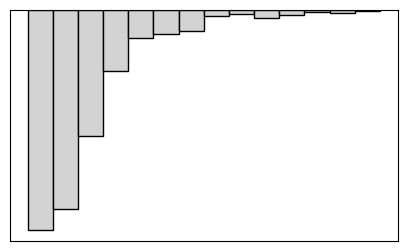

In [3]:
''' LCs from the entire dataset '''
corr = np.corrcoef(data.T)
eigvals,eigvects = np.linalg.eigh(corr)
argsort = np.argsort(eigvals)

eigvals = eigvals[argsort]
full_eigvects = eigvects[:,argsort]

full_eigvects[:,2] *= -1 #flip it so sign is consistent with what is shown in the manuscript

mode = 0
fig,ax = plt.subplots(figsize=(5,3))
ax.bar(np.arange(N),
       full_eigvects[:,mode],
       width=1, edgecolor='k',facecolor='lightgray')
ax.set_xticks([])
ax.set_yticks([])


In [4]:
N_bootstraps = 1000
bootstrapped_eigvects = np.zeros((N_bootstraps,N,N))
np.random.seed(30) #set random seed.
for i in range(N_bootstraps):
    ''' LCs from subsampled dataset '''
    bootstrapped_samples = np.random.choice(np.arange(M),
                                          size = M, #Sample M samples with replacement for bootstrapping
                                          replace=True
                                         )
    bootstrapped_data = data[bootstrapped_samples,:]
    corr = np.corrcoef(bootstrapped_data.T)
    eigvals,eigvects = np.linalg.eigh(corr)
    argsort = np.argsort(eigvals)
    
    eigvals = eigvals[argsort]
    eigvects = eigvects[:,argsort]

    ''' Align eigvects from this run with original_eigvects '''
    inverted_sign = np.diagonal(eigvects.T @ full_eigvects)<0
    eigvects[:,inverted_sign] *= -1 #align eigvects of the bootstrap with original eigvects

    bootstrapped_eigvects[i,:,:] = eigvects


eigvect_stds = np.std(bootstrapped_eigvects,axis=0)


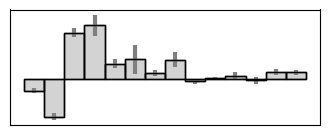

In [10]:
mode = 1
fig,ax = plt.subplots(figsize=(4,1.5))
ax.bar(np.arange(N),
       full_eigvects[:,mode],
       width=1, edgecolor='k',facecolor='lightgray')
ax.errorbar(np.arange(N),
        full_eigvects[:,mode],
        yerr = eigvect_stds[:,mode],
        linestyle='none',
        color='gray',linewidth=3
        )
ax.bar(np.arange(N),
       full_eigvects[:,mode],
       linewidth=1,
       width=1, edgecolor='k',facecolor='none',zorder=3)
ax.set_xticks([])
ax.set_yticks([])
plt.savefig('{}.LC{}.svg'.format(dataset_name,mode+1))